# 02 · Gaze analysis
I-DT fixations, AOI assignment, metrics, scanpaths and heatmaps.

> **Prerequisite:** `python -m gazegrounded.cli run-all` (synthetic demo).
>
> All logic lives in `src/gazegrounded/`; this notebook only calls it. With the synthetic config every number is **SYNTHETIC DEMO DATA — NOT RESEARCH EVIDENCE**.

In [1]:
from pathlib import Path
import os
# Run from the repository root so relative config paths resolve.
while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir("..")
import numpy as np
import pandas as pd
from gazegrounded.config import load_config
from gazegrounded.data.loader import load_processed
from gazegrounded.utils import SYNTHETIC_BANNER
cfg = load_config("configs/synthetic.yaml")  # switch to configs/experiment.yaml for real data
ds = load_processed(cfg)
print(SYNTHETIC_BANNER if ds.is_synthetic else "Real data:", cfg.data.source)

SYNTHETIC DEMO DATA — NOT RESEARCH EVIDENCE synthetic


In [2]:
from gazegrounded.gaze.fixation import detect_fixations
from gazegrounded.gaze.aoi import assign_fixations_to_aois
g = cfg.gaze
fix = detect_fixations(ds.gaze_samples, g.dispersion_threshold_px, g.minimum_duration_ms, g.max_gap_ms)
fix = assign_fixations_to_aois(fix, ds.aois, ds.uis, g.aoi_margin_px)
fix['duration_ms'].describe().round(0)

count    1738.0
mean      274.0
std       154.0
min       100.0
25%       167.0
50%       233.0
75%       350.0
max      1317.0
Name: duration_ms, dtype: float64

### Sensitivity of I-DT to its dispersion threshold
A documented limitation: the threshold changes how many fixations are found.

In [3]:
for thr in (40, 60, 80, 120):
    n = len(detect_fixations(ds.gaze_samples, thr, g.minimum_duration_ms, g.max_gap_ms))
    print(f'dispersion {thr:4d} px -> {n} fixations')

dispersion   40 px -> 2226 fixations


dispersion   60 px -> 1839 fixations
dispersion   80 px -> 1738 fixations


dispersion  120 px -> 1678 fixations


In [4]:
from gazegrounded.gaze.metrics import compute_gaze_metrics
tm, am = compute_gaze_metrics(ds, fix, g.aoi_margin_px)
tm.merge(ds.trials[['trial_id','condition']]).groupby('condition')[['ttff_ms','fixation_count','revisit_count','aoi_transition_count','task_relevant_attention']].mean().round(2)

,ttff_ms,fixation_count,revisit_count,aoi_transition_count,task_relevant_attention
condition,,,,,
clean,1302.43,8.06,0.90,4.81,0.38
friction,4191.09,21.42,9.00,15.92,0.22
single,2221.53,13.46,4.17,8.96,0.27


In [5]:
from gazegrounded.gaze.scanpath import aoi_sequence, format_scanpath, transition_matrix
trial = ds.trials[ds.trials.condition=='friction'].iloc[0]
f = fix[fix.trial_id==trial.trial_id]
print(trial.task_description)
print(format_scanpath(aoi_sequence(f), max_len=20))
transition_matrix(aoi_sequence(f))

Change the delivery address for this order.
address_card → header → delivery_options → discount_link → promo_banner → header → payment → order_summary → progress → place_order → order_summary → delivery_options → title → delivery_options → place_order → promo_banner → progress → title → edit_address_link → … → edit_address_link


,address_card,delivery_options,discount_link,edit_address_link,header,order_summary,payment,place_order,progress,promo_banner,title
address_card,0,0,0,0,1,0,0,0,0,0,0
delivery_options,0,0,1,0,0,0,0,1,0,0,1
discount_link,0,0,0,1,0,0,0,0,0,1,0
edit_address_link,0,0,1,0,0,0,0,0,0,0,2
header,0,1,0,0,0,0,1,0,0,0,0
order_summary,0,1,0,0,0,0,0,0,1,0,0
payment,0,0,0,0,0,1,0,0,0,0,0
place_order,0,0,0,0,0,1,0,0,0,1,0
progress,0,0,0,0,0,0,0,1,0,0,1
promo_banner,0,0,0,0,1,0,0,0,1,0,0


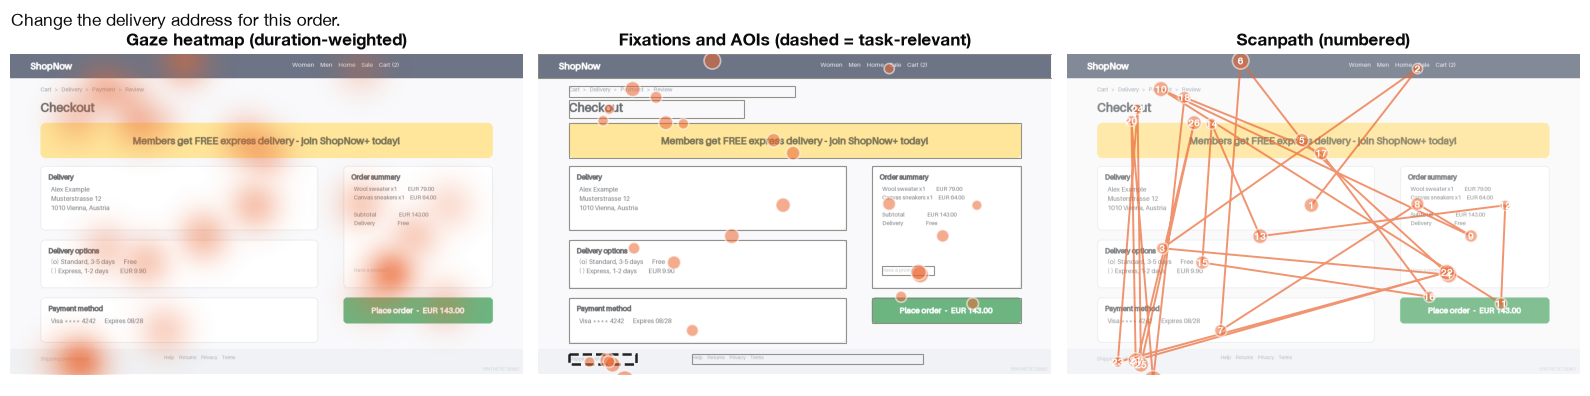

In [6]:
%matplotlib inline
from gazegrounded.gaze.heatmap import fixation_heatmap
from gazegrounded.visualization.gaze import trial_figure, load_image
w, h = ds.ui_size(trial.ui_id)
fig = trial_figure(load_image(ds.image_path(trial.ui_id)), f, ds.aois_for(trial.ui_id), ds.targets_for_task(trial.task_id), fixation_heatmap(f, w, h, g.heatmap_sigma_px, 0.5), trial.task_description)